In [1]:
import os
from google.colab import drive
import numpy as np
import pandas as pd

drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google.colab'

In [ ]:
from scipy.stats import bernoulli
from scipy.linalg import sqrtm
from sklearn.utils.extmath import randomized_svd
#from numpy import random
import math
#import igraph
import random
import time
import functorch
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from numpy.linalg import inv
from numpy.linalg import det
from numpy import log, prod, absolute, exp, pi, trace, dot, cumsum, \
                  hstack, ix_, sqrt, eye, diag, array, sum

In [ ]:
###main function

def sample_graph(adj_A, sel_nodes):
    A11 = torch.index_select(adj_A, dim = 0, index = sel_nodes)
    A12 = torch.index_select(A11, dim = 1, index = sel_nodes)
    return A12

def generate_adj(pm):
    nodes = pm.shape[0]
    A = torch.bernoulli(pm)
    i, j = torch.triu_indices(nodes, nodes)
    vals = A[i,j]
    A.T[i, j] = vals
    return A


def get_emded_gpu_origin(A,d):
    d = d
    w, lamb = torch.linalg.eigh(A)
    sortedEig, indices=torch.sort(w, dim=0, descending=True, out=None)
    indices1 = indices[0:d]
    lambSort = torch.index_select(lamb, dim = 1, index = indices1)
    diag_eigval = torch.diag(torch.sqrt(sortedEig[0:d]))
    lpvs = torch.matmul(lambSort, diag_eigval)
    phat = torch.matmul(lpvs, lpvs.T)
    return phat

def get_emded_gpu_fast(lamb,sortedEig,d):
    d = d
    lambSort = lamb[:,0:d]
    diag_eigval = torch.diag(torch.sqrt(sortedEig[0:d]))
    lpvs = torch.matmul(lambSort, diag_eigval)
    phat = torch.matmul(lpvs, lpvs.T)
    return phat

def pd_transformation(A):
    A1 = torch.matmul(A.T,A)
    A2 = torch.Tensor(sqrtm(A1))
    return A2

def generate_M_univariate(nodes,cov_val,M):
    mean = torch.zeros(M)
    cov = torch.zeros(M,M)
    i, j = torch.triu_indices(M,M)
    cov[i, j] = cov_val
    cov.T[i,j] = cov_val
    cov.fill_diagonal_(1)
    x = np.random.multivariate_normal(mean, cov, nodes).T
    return x

def generate_probability_matrix(x,nodes):
    pm_tensor = torch.ones(nodes, nodes, dtype=torch.float64)
    i, j = torch.triu_indices(nodes,nodes)
    pm_var = torch.exp(-torch.pow(x[i]-x[j],2))
    pm_tensor[i, j] = pm_var
    pm_tensor.T[i,j] = pm_var
    #pm_tensor.fill_diagonal_(0)
    return pm_tensor

def get_approx_svd(matrix,d0):
    U, Sigma, VT = randomized_svd(np.array(matrix),
                              n_components=d0,
                              n_iter=5)
    return U, Sigma


def get_opt_embed_fast(Sigma,nodes):
    decay_rate = -np.log(Sigma[0])
    opt_embed = np.log(nodes)/(3*decay_rate)
    return round(opt_embed.item())

def get_opt_embed_poly_fast(Sigma,nodes):
    index = np.linspace(1, d1, num=d1).tolist()
    Sigma = Sigma.tolist()
    y = np.array([np.log(x) for x in Sigma])
    x = np.array([np.log(x) for x in index])
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    decay_rate = -slope
    pow = (alpha+1)/((3*alpha+1)*alpha)
    opt_embed = np.power(nodes,pow)
    return round(opt_embed.item())


def get_opt_embed(matrix,nodes):
    w, lamb = torch.linalg.eigh(matrix/nodes)
    sortedEig, indices=torch.sort(w, dim=0, descending=True, out=None)
    decay_rate = -np.log(sortedEig[0])
    opt_embed = np.log(nodes)/(3*decay_rate)
    return round(opt_embed.item())

def cal_product_k(tensor):
    M = tensor.shape[0]
    nodes = tensor.shape[1]
    k0 = torch.ones(nodes,nodes)
    for i in range(M):
        k0 = torch.mul(k0,tensor[i])
    return k0

def hat_GHSIC(tensor):
    k = cal_product_k(tensor)
    n = nodes
    vec1 = torch.ones(n,dtype=torch.float32)
    r1 = torch.matmul(torch.matmul(vec1.T,k),vec1)/(n*n)
    M = tensor.shape[0]
    r2 = 1
    r3 = 1
    for i in range(M):
        r2 = r2*(torch.matmul(torch.matmul(vec1.T,tensor[i]),vec1)/(n*n))
        r3 = r3*(torch.matmul(tensor[i],vec1)/n)
    r3 = torch.matmul(vec1.T,r3)/n
    est = r1 + r2 - 2*r3
    return est

def get_pval(bootsam,tensor,stat):
    sum_gre = 0
    sel_n = nodes
    for k in range(bootsam.shape[1]):
        embed_tensor1 = torch.zeros(M,nodes, nodes)
        for i in range(M):
            embed_tensor1[i] = sample_graph(tensor[i], bootsam[i,k,:])
        est_GHSIC1 = hat_GHSIC(embed_tensor1)
        sum_gre = sum_gre + np.greater_equal(est_GHSIC1, stat)
    pval = (1+sum_gre)/(1+n_boot)
    return pval

In [ ]:
from nilearn.connectome import ConnectivityMeasure
from nilearn.maskers import MultiNiftiLabelsMasker,NiftiMapsMasker
from nilearn import plotting
from nilearn import datasets
#from nilearn.input_data import NiftiLabelsMasker

import scipy.ndimage as ndi
from nilearn import image as nli
import matplotlib.pyplot as plt

## Map BOLD to brain map

In [ ]:
dataset = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=1, data_dir=None, base_url=None, resume=True, verbose=1)
atlas_filename = dataset.maps
labels = dataset.labels

[fetch_atlas_schaefer_2018] Dataset directory found: /root/nilearn_data/schaefer_2018

[fetch_atlas_schaefer_2018] Downloading data from https://raw.githubusercontent.com/ThomasYeoLab/CBIG/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/Schaefer2018_400Parcels_7Networks_order.txt ...

[fetch_atlas_schaefer_2018]  ...done. (0 seconds, 0 min)

[fetch_atlas_schaefer_2018] Downloading data from https://raw.githubusercontent.com/ThomasYeoLab/CBIG/v0.14.3-Update_Yeo2011_Schaefer2018_labelname/stable_projects/brain_parcellation/Schaefer2018_LocalGlobal/Parcellations/MNI/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz ...

[fetch_atlas_schaefer_2018]  ...done. (0 seconds, 0 min)

In [ ]:
subj = ['sub-UTS01','sub-UTS02','sub-UTS03','sub-UTS04','sub-UTS05','sub-UTS06','sub-UTS07','sub-UTS08']

In [ ]:
sess = ['ses-2','ses-3','ses-4','ses-5','ses-6']

In [ ]:
parent_dir = '/content/drive/MyDrive/brain_data/numpy_data/'

for i in subj:
  for j in sess:
    path = os.path.join(parent_dir, i, j)
    os.makedirs(path)

FileExistsError: [Errno 17] File exists: '/content/drive/MyDrive/brain_data/numpy_data/sub-UTS01/ses-2'

In [ ]:
save_dir = '/content/drive/MyDrive/brain_data/numpy_data/'
parent_dir = '/content/drive/MyDrive/brain_data/ds003020/'

for i in subj:
  for j in sess:
    path = os.path.join(parent_dir, i, j,'func')
    file_list =  os.listdir(path)
    sel_file = [s for s in file_list if 'nii' in s]
    for k in sel_file:
      file_path = os.path.join(parent_dir, i, j,'func',k)
      brain_vol = nli.load_img(file_path)
      masker = NiftiLabelsMasker(
          labels_img=atlas_filename,
          standardize="zscore_sample",
          standardize_confounds="zscore_sample",
          memory="nilearn_cache",
          verbose=5)
      time_series = masker.fit_transform(brain_vol)
      name = k.split('nii')[0] + str('npy')
      outfile = os.path.join(save_dir,i,j,name)
      np.save(outfile, time_series)
      print(time_series.shape)

[NiftiLabelsMasker.wrapped] loading data from /root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
Resampling labels
________________________________________________________________________________
[Memory] Calling nilearn.maskers.base_masker._filter_and_extract...
_filter_and_extract(<nibabel.nifti1.Nifti1Image object at 0x7986703092a0>, <nilearn.maskers.nifti_labels_masker._ExtractionFunctor object at 0x7986a98eb5b0>, 
{ 'background_label': 0,
  'clean_kwargs': {},
  'detrend': False,
  'dtype': None,
  'high_pass': None,
  'high_variance_confounds': False,
  'keep_masked_labels': True,
  'labels': None,
  'labels_img': '/root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz',
  'low_pass': None,
  'mask_img': None,
  'reports': True,
  'smoothing_fwhm': None,
  'standardize': 'zscore_sample',
  'standardize_confounds': 'zscore_sample',
  'strategy': 'mean',
  't_r': None,
  'target_affine': None,
  'targ

/usr/local/lib/python3.10/dist-packages/nilearn/maskers/nifti_labels_masker.py:724: UserWarning: Persisting input arguments took 1.28s to run.If this happens often in your code, it can cause performance problems (results will be correct in all cases). The reason for this is probably some large input arguments for a wrapped function.
  region_signals, (ids, masked_atlas) = self._cache(


______________________________________________filter_and_extract - 11.8s, 0.2min
(363, 400)
[NiftiLabelsMasker.wrapped] loading data from /root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
Resampling labels
________________________________________________________________________________
[Memory] Calling nilearn.maskers.base_masker._filter_and_extract...
_filter_and_extract(<nibabel.nifti1.Nifti1Image object at 0x7986a99190c0>, <nilearn.maskers.nifti_labels_masker._ExtractionFunctor object at 0x7986716e0f10>, 
{ 'background_label': 0,
  'clean_kwargs': {},
  'detrend': False,
  'dtype': None,
  'high_pass': None,
  'high_variance_confounds': False,
  'keep_masked_labels': True,
  'labels': None,
  'labels_img': '/root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz',
  'low_pass': None,
  'mask_img': None,
  'reports': True,
  'smoothing_fwhm': None,
  'standardize': 'zscore_sample',
  'standardize_confou

/usr/local/lib/python3.10/dist-packages/nilearn/maskers/nifti_labels_masker.py:724: UserWarning: Persisting input arguments took 1.14s to run.If this happens often in your code, it can cause performance problems (results will be correct in all cases). The reason for this is probably some large input arguments for a wrapped function.
  region_signals, (ids, masked_atlas) = self._cache(


______________________________________________filter_and_extract - 11.8s, 0.2min
(387, 400)
[NiftiLabelsMasker.wrapped] loading data from /root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
Resampling labels
________________________________________________________________________________
[Memory] Calling nilearn.maskers.base_masker._filter_and_extract...
_filter_and_extract(<nibabel.nifti1.Nifti1Image object at 0x7986702d0250>, <nilearn.maskers.nifti_labels_masker._ExtractionFunctor object at 0x7986a9919780>, 
{ 'background_label': 0,
  'clean_kwargs': {},
  'detrend': False,
  'dtype': None,
  'high_pass': None,
  'high_variance_confounds': False,
  'keep_masked_labels': True,
  'labels': None,
  'labels_img': '/root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz',
  'low_pass': None,
  'mask_img': None,
  'reports': True,
  'smoothing_fwhm': None,
  'standardize': 'zscore_sample',
  'standardize_confou

...

/usr/local/lib/python3.10/dist-packages/nilearn/maskers/nifti_labels_masker.py:724: UserWarning: Persisting input arguments took 1.19s to run.If this happens often in your code, it can cause performance problems (results will be correct in all cases). The reason for this is probably some large input arguments for a wrapped function.
  region_signals, (ids, masked_atlas) = self._cache(


______________________________________________filter_and_extract - 12.7s, 0.2min
(405, 400)
[NiftiLabelsMasker.wrapped] loading data from /root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
Resampling labels
________________________________________________________________________________
[Memory] Calling nilearn.maskers.base_masker._filter_and_extract...
_filter_and_extract(<nibabel.nifti1.Nifti1Image object at 0x7986703bc580>, <nilearn.maskers.nifti_labels_masker._ExtractionFunctor object at 0x7986703bf0a0>, 
{ 'background_label': 0,
  'clean_kwargs': {},
  'detrend': False,
  'dtype': None,
  'high_pass': None,
  'high_variance_confounds': False,
  'keep_masked_labels': True,
  'labels': None,
  'labels_img': '/root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz',
  'low_pass': None,
  'mask_img': None,
  'reports': True,
  'smoothing_fwhm': None,
  'standardize': 'zscore_sample',
  'standardize_confou

/usr/local/lib/python3.10/dist-packages/nilearn/maskers/nifti_labels_masker.py:724: UserWarning: Persisting input arguments took 0.92s to run.If this happens often in your code, it can cause performance problems (results will be correct in all cases). The reason for this is probably some large input arguments for a wrapped function.
  region_signals, (ids, masked_atlas) = self._cache(


_______________________________________________filter_and_extract - 9.1s, 0.2min
(311, 400)
[NiftiLabelsMasker.wrapped] loading data from /root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz
Resampling labels
________________________________________________________________________________
[Memory] Calling nilearn.maskers.base_masker._filter_and_extract...
_filter_and_extract(<nibabel.nifti1.Nifti1Image object at 0x7986702d14e0>, <nilearn.maskers.nifti_labels_masker._ExtractionFunctor object at 0x7986702d3df0>, 
{ 'background_label': 0,
  'clean_kwargs': {},
  'detrend': False,
  'dtype': None,
  'high_pass': None,
  'high_variance_confounds': False,
  'keep_masked_labels': True,
  'labels': None,
  'labels_img': '/root/nilearn_data/schaefer_2018/Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.nii.gz',
  'low_pass': None,
  'mask_img': None,
  'reports': True,
  'smoothing_fwhm': None,
  'standardize': 'zscore_sample',
  'standardize_confou

/usr/local/lib/python3.10/dist-packages/nilearn/maskers/nifti_labels_masker.py:724: UserWarning: Persisting input arguments took 1.42s to run.If this happens often in your code, it can cause performance problems (results will be correct in all cases). The reason for this is probably some large input arguments for a wrapped function.
  region_signals, (ids, masked_atlas) = self._cache(


In [ ]:
path = '/content/drive/MyDrive/brain_data/numpy_data/sub-UTS01/ses-2'
file_list =  os.listdir(path)

In [ ]:
file_list

['sub-UTS01_ses-2_task-alternateithicatom_bold.npy',
 'sub-UTS01_ses-2_task-avatar_bold.npy',
 'sub-UTS01_ses-2_task-odetostepfather_bold.npy',
 'sub-UTS01_ses-2_task-wheretheressmoke_run-1_bold.npy',
 'sub-UTS01_ses-2_task-souls_bold.npy',
 'sub-UTS01_ses-2_task-legacy_bold.npy']

In [ ]:
file_name = os.path.join(path,file_list[1])

task1 = np.load(file_name)
task1.shape

(387, 400)

In [ ]:
task1_df = pd.DataFrame(task1)
task1_df = task1_df.T

In [ ]:
#task1_df = task1_df.T
task1_df.head()

,0,1,2,3,4,5,6,7,8,9,...,377,378,379,380,381,382,383,384,385,386
0,0.551737,1.528509,1.689888,1.741876,1.185622,0.669163,1.756267,1.324715,-0.197537,1.104413,...,-2.110886,-1.507382,-1.600364,-0.718233,-0.523054,-1.572341,-0.874915,-1.641818,-0.934638,-0.055086
1,2.117206,1.595990,0.534684,1.797731,1.938289,1.198221,0.619442,1.769619,0.734286,-0.424259,...,-2.179070,-2.240065,-0.909231,-0.012669,-0.828869,-1.603253,-0.735814,-0.716258,-0.487017,0.494468
2,0.771489,0.650909,-0.276825,-0.816210,-0.057293,-0.273436,-0.074796,-1.816286,-0.866748,-0.410179,...,-1.118279,-0.083017,0.479335,-0.367760,0.235494,0.709061,0.857946,-0.502884,1.236380,-0.827542
3,0.479114,-0.639794,1.250731,0.764848,-0.597876,-0.025869,1.254640,0.885230,-0.230691,-0.935570,...,-0.384855,-1.491845,-0.083677,1.484314,1.377088,1.713034,1.120656,1.293888,1.565098,-0.408468
4,0.173701,-0.673833,0.871890,0.319381,-0.027563,-0.336840,0.524997,0.703967,1.033273,-0.231703,...,-1.269507,-0.873036,-0.380208,-0.061387,1.050249,1.164523,0.554469,0.474681,1.008535,-1.149150


In [ ]:
labels[:5]

['Background',
 '7Networks_LH_Vis_1',
 '7Networks_LH_Vis_2',
 '7Networks_LH_Vis_3',
 '7Networks_LH_Vis_4']

In [ ]:
label_list = labels[1:401]
#label_list = [x.astype('str') for x in label_list]
label_list[:5]

['7Networks_LH_Vis_1',
 '7Networks_LH_Vis_2',
 '7Networks_LH_Vis_3',
 '7Networks_LH_Vis_4',
 '7Networks_LH_Vis_5']

In [ ]:
len(label_list)

400

In [ ]:
task1_df.index = label_list
task1_df.head()

,0,1,2,3,4,5,6,7,8,9,...,377,378,379,380,381,382,383,384,385,386
7Networks_LH_Vis_1,0.551737,1.528509,1.689888,1.741876,1.185622,0.669163,1.756267,1.324715,-0.197537,1.104413,...,-2.110886,-1.507382,-1.600364,-0.718233,-0.523054,-1.572341,-0.874915,-1.641818,-0.934638,-0.055086
7Networks_LH_Vis_2,2.117206,1.595990,0.534684,1.797731,1.938289,1.198221,0.619442,1.769619,0.734286,-0.424259,...,-2.179070,-2.240065,-0.909231,-0.012669,-0.828869,-1.603253,-0.735814,-0.716258,-0.487017,0.494468
7Networks_LH_Vis_3,0.771489,0.650909,-0.276825,-0.816210,-0.057293,-0.273436,-0.074796,-1.816286,-0.866748,-0.410179,...,-1.118279,-0.083017,0.479335,-0.367760,0.235494,0.709061,0.857946,-0.502884,1.236380,-0.827542
7Networks_LH_Vis_4,0.479114,-0.639794,1.250731,0.764848,-0.597876,-0.025869,1.254640,0.885230,-0.230691,-0.935570,...,-0.384855,-1.491845,-0.083677,1.484314,1.377088,1.713034,1.120656,1.293888,1.565098,-0.408468
7Networks_LH_Vis_5,0.173701,-0.673833,0.871890,0.319381,-0.027563,-0.336840,0.524997,0.703967,1.033273,-0.231703,...,-1.269507,-0.873036,-0.380208,-0.061387,1.050249,1.164523,0.554469,0.474681,1.008535,-1.149150


In [ ]:
Vis_label = [s for s in label_list if 'Vis' in s]
SomMot_label = [s for s in label_list if 'SomMot' in s]
DorsAttn_label = [s for s in label_list if 'DorsAttn' in s]
SalVentAttn_label = [s for s in label_list if 'SalVentAttn' in s]
Limbic_label = [s for s in label_list if 'Limbic' in s]
Cont_label = [s for s in label_list if 'Cont' in s]
Default_label = [s for s in label_list if 'Default' in s]

In [ ]:
def get_adj_mat(df,threshold):
  mat_corr = np.corrcoef(df)
  mat_corr = np.abs(mat_corr)
  mat_corr[mat_corr < threshold] = 0
  mat_corr[mat_corr >= threshold] = 1
  np.fill_diagonal(mat_corr, 0, wrap=True)
  return torch.Tensor(mat_corr)

In [ ]:
pval_df1 = np.zeros((len(sess),len(subj)))
GHSIC_df1 = np.zeros((len(sess),len(subj)))

In [ ]:
subj

['sub-UTS01',
 'sub-UTS02',
 'sub-UTS03',
 'sub-UTS04',
 'sub-UTS05',
 'sub-UTS06',
 'sub-UTS07',
 'sub-UTS08']

In [ ]:
sess

['ses-2', 'ses-3', 'ses-4', 'ses-5', 'ses-6']

## check the sepctral decay type

In [ ]:
path = '/content/drive/MyDrive/brain_data/numpy_data/'
threshold = 0.5
sess_path = os.path.join(path,subj[0],sess[0])
file_list =  os.listdir(sess_path)
file_list[0]

'sub-UTS01_ses-2_task-alternateithicatom_bold.npy'

In [ ]:
nodes = len(Default_label)

file_name = os.path.join(sess_path,file_list[2])
task = np.load(file_name)

task_df = pd.DataFrame(task).T
task_df.index = label_list
task_sel = task_df.loc[Default_label, :]
adj_tensor = get_adj_mat(task_sel,threshold)

In [ ]:
A1 = torch.matmul(adj_tensor.T,adj_tensor)
w, lamb = torch.linalg.eigh(adj_tensor)

In [ ]:
sortedEig, indices=torch.sort(w, dim=0, descending=True, out=None)

In [ ]:
sortedEig = np.sqrt(sortedEig/(nodes*nodes))

/tmp/ipykernel_4981/2358019842.py:1: RuntimeWarning: invalid value encountered in sqrt
  sortedEig = np.sqrt(sortedEig/(nodes*nodes))
/tmp/ipykernel_4981/2358019842.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sortedEig = np.sqrt(sortedEig/(nodes*nodes))


In [ ]:
sel_Eig = sortedEig[:10]
sel_Eig

tensor([0.0659, 0.0389, 0.0367, 0.0346, 0.0295, 0.0274, 0.0231, 0.0220, 0.0201,
        0.0194])

In [ ]:
index = np.linspace(1, 10, num=10).tolist()
index[:5]

[1.0, 2.0, 3.0, 4.0, 5.0]

In [ ]:
sel_Eig = sel_Eig.tolist()
sel_Eig[:5]

[0.0658901259303093,
 0.03885488584637642,
 0.03669484704732895,
 0.034606482833623886,
 0.02953501045703888]

In [ ]:
fit_df = pd.DataFrame(
    data= {
        'log_lambda':[np.log(x) for x in sel_Eig],
        'index':index,
        'log_index':[np.log(x) for x in index]
    }
)
fit_df.head()

,log_lambda,index,log_index
0,-2.719767,1.0,0.000000
1,-3.247921,2.0,0.693147
2,-3.305119,3.0,1.098612
3,-3.363714,4.0,1.386294
4,-3.522179,5.0,1.609438


In [ ]:
import numpy as np
from scipy.stats import linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error

# input data
y = np.array([np.log(x) for x in sel_Eig])
x = np.array(index)

# scipy linear regression
slope, intercept, r_value, p_value, std_err = linregress(x, y)
y_pred = intercept + slope * x

mse = mean_squared_error(y_true=y, y_pred=y_pred)
rmse = root_mean_squared_error(y_true=y, y_pred=y_pred)

print('scipy intercept: {:.6f}'.format(intercept))
print('scipy slope: {:.6f}'.format(slope))
print('scipy MSE: {:.6f}'.format(mse))
print('scipy RMSE: {:.6f}'.format(rmse))

scipy intercept: -2.869939
scipy slope: -0.118078
scipy MSE: 0.012039
scipy RMSE: 0.109723


In [ ]:
# input data
y = np.array([np.log(x) for x in sel_Eig])
x = np.array([np.log(x) for x in index])

# scipy linear regression
slope, intercept, r_value, p_value, std_err = linregress(x, y)
y_pred = intercept + slope * x

mse = mean_squared_error(y_true=y, y_pred=y_pred)
rmse = root_mean_squared_error(y_true=y, y_pred=y_pred)

print('scipy intercept: {:.6f}'.format(intercept))
print('scipy slope: {:.6f}'.format(slope))
print('scipy MSE: {:.6f}'.format(mse))
print('scipy RMSE: {:.6f}'.format(rmse))

scipy intercept: -2.757196
scipy slope: -0.504602
scipy MSE: 0.003930
scipy RMSE: 0.062692


In [ ]:
def get_opt_embed_poly_fast(Sigma,nodes):
    index = np.linspace(1, d1, num=d1).tolist()
    Sigma = Sigma.tolist()
    y = np.array([np.log(x) for x in Sigma])
    x = np.array([np.log(x) for x in index])
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    decay_rate = -slope
    pow = (alpha+1)/((3*alpha+1)*alpha)
    opt_embed = np.power(nodes,pow)
    return round(opt_embed.item())

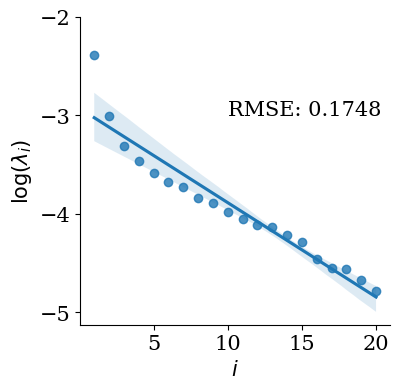

In [ ]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

fig, ax = plt.subplots(figsize=(4, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


params = {'legend.fontsize': 12,
          'axes.labelsize': 15,
          'axes.titlesize': 15,
          'xtick.labelsize': 15,
          'ytick.labelsize': 15,
          'text.usetex': False,
          #'font.family': "Times New Roman",
          'text.latex.preamble': r'\usepackage{amsfonts}'}
plt.rcParams.update(params)

g = sns.regplot(data=fit_df, x="index", y="log_lambda")

#ax.set_title('Exponential Decay Fitting',fontsize=15)
ax.text(10, -3, "RMSE: 0.1748",fontsize=15)

g.set(ylabel=r'$\log(\lambda_{i})$')
g.set(xlabel=r'$i$')
g.set(yticks=[-5,-4,-3,-2])
g.set(xticks=[5,10,15,20])

plt.savefig('/content/drive/MyDrive/brain_data/Exponential_fit.svg', format='svg',bbox_inches="tight")

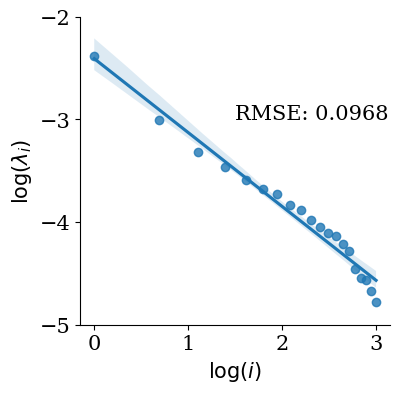

In [ ]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

fig, ax = plt.subplots(figsize=(4, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


params = {'legend.fontsize': 12,
          'axes.labelsize': 15,
          'axes.titlesize': 15,
          'xtick.labelsize': 15,
          'ytick.labelsize': 15,
          'text.usetex': False,
          #'font.family': "Times New Roman",
          'text.latex.preamble': r'\usepackage{amsfonts}'}
plt.rcParams.update(params)

g = sns.regplot(data=fit_df, x="log_index", y="log_lambda")

#ax.set_title('Polynomial Decay Fitting',fontsize=15)
ax.text(1.5, -3, "RMSE: 0.0968",fontsize=15)

g.set(ylabel=r'$\log(\lambda_{i})$')
g.set(xlabel=r'$\log(i)$')
g.set(yticks=[-5,-4,-3,-2])

plt.savefig('/content/drive/MyDrive/brain_data/Polynomial_fit.svg', format='svg',bbox_inches="tight")

In [ ]:
sel_file = [s for s in file_list if not 'run' in s]
sel_file

['sub-UTS01_ses-3_task-howtodraw_bold.npy',
 'sub-UTS01_ses-3_task-myfirstdaywiththeyankees_bold.npy',
 'sub-UTS01_ses-3_task-life_bold.npy',
 'sub-UTS01_ses-3_task-undertheinfluence_bold.npy',
 'sub-UTS01_ses-3_task-naked_bold.npy']

In [ ]:
path = '/content/drive/MyDrive/brain_data/numpy_data/'

sess_path = os.path.join(path,subj[0],sess[1])
file_list =  os.listdir(sess_path)
file_list = [s for s in file_list if not 'run' in s]
file_list

['sub-UTS01_ses-3_task-howtodraw_bold.npy',
 'sub-UTS01_ses-3_task-myfirstdaywiththeyankees_bold.npy',
 'sub-UTS01_ses-3_task-life_bold.npy',
 'sub-UTS01_ses-3_task-undertheinfluence_bold.npy',
 'sub-UTS01_ses-3_task-naked_bold.npy']

In [ ]:
pval_df1 = np.zeros((len(sess),len(subj)))
GHSIC_df1 = np.zeros((len(sess),len(subj)))

In [ ]:
path = '/content/drive/MyDrive/brain_data/numpy_data/'
threshold = 0.4
n_boot = 500

subnet = ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']

for s in range(len(sess)):
  for p in range(len(subj)):
    sess_path = os.path.join(path,subj[p],sess[s])
    file_list =  os.listdir(sess_path)
    file_list = [s for s in file_list if not 'run' in s]

    M = len(file_list)
    nodes = len(SalVentAttn_label)
    adj_tensor = torch.zeros(M,nodes, nodes)
    embed_para = torch.zeros(M)
    embed_tensor = torch.zeros(M,nodes, nodes)

    for i in range(M):
      file_name = os.path.join(sess_path,file_list[i])
      task = np.load(file_name)
      task_df = pd.DataFrame(task).T
      task_df.index = label_list
      task_sel = task_df.loc[SalVentAttn_label, :]
      adj_tensor[i] = get_adj_mat(task_sel,threshold)
      d1 = 10
      A1 = torch.matmul(adj_tensor[i].T,adj_tensor[i])
      U, Sigma = get_approx_svd(A1,d1)
      Sigma0 = np.sqrt(Sigma/(nodes*nodes))
      Sigma1 = np.sqrt(Sigma)
      embed_para[i] = get_opt_embed_poly_fast(Sigma0,nodes)
      embed_tensor[i] = get_emded_gpu_fast(torch.Tensor(U),torch.Tensor(Sigma1),int(embed_para[i].item()))
    est_GHSIC = hat_GHSIC(embed_tensor)
    GHSIC_df1[s,p] = est_GHSIC.item()
    sel_n = nodes
    bootsam = np.zeros((M,n_boot, sel_n), int)
    for i in range(M):
        for m in range(n_boot):
            bootsam[i,m,:] = random.sample(range(0,nodes),sel_n)
    bootsam = torch.from_numpy(bootsam)
    gcorr_pval = get_pval(bootsam,embed_tensor,est_GHSIC)
    print(est_GHSIC.item(),gcorr_pval.item())
    pval_df1[s,p] = gcorr_pval.item()

0.045183323323726654 0.0019960079807788134
0.0870792344212532 0.0019960079807788134
0.0687774270772934 0.0019960079807788134
0.08116869628429413 0.0019960079807788134
0.05370692163705826 0.0019960079807788134
0.0888851135969162 0.0019960079807788134
0.0581434965133667 0.0019960079807788134
0.026331717148423195 0.0019960079807788134
0.0589793398976326 0.0019960079807788134
0.05797204375267029 0.0019960079807788134
0.06460902094841003 0.0019960079807788134
0.057272642850875854 0.0019960079807788134
0.10345158725976944 0.0019960079807788134
0.08782894909381866 0.0019960079807788134
0.020880285650491714 0.0019960079807788134
0.02864384651184082 0.0019960079807788134
0.06592750549316406 0.0019960079807788134
0.0476330891251564 0.0019960079807788134
0.08149793744087219 0.0019960079807788134
0.07501566410064697 0.0019960079807788134
0.05067853629589081 0.0019960079807788134
0.08024206757545471 0.0019960079807788134
0.04784214496612549 0.0019960079807788134
0.05414372682571411 0.00199600798077

In [ ]:
pd.DataFrame(pval_df1).to_csv('/content/drive/MyDrive/brain_data/no_run/DorsAttn_pval_thre08.csv')
#pd.DataFrame(GHSIC_df1).to_csv('/content/drive/MyDrive/brain_data/Default_GHSIC_thre07.csv')

In [ ]:
path = '/content/drive/MyDrive/brain_data/numpy_data/'
threshold = 0.5
n_boot = 500

subnet = ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']

all_mean = torch.zeros(len(Limbic_label))

for s in range(len(sess)):
  for p in range(len(subj)):
    sess_path = os.path.join(path,subj[p],sess[s])
    file_list =  os.listdir(sess_path)
    M = len(file_list)
    nodes = len(Limbic_label)
    adj_tensor = torch.zeros(M,nodes, nodes)
    deg = torch.zeros(nodes)
    mean_deg = torch.zeros(nodes)
    for i in range(M):
      file_name = os.path.join(sess_path,file_list[i])
      task = np.load(file_name)
      task_df = pd.DataFrame(task).T
      task_df.index = label_list
      task_sel = task_df.loc[Limbic_label, :]
      adj_tensor[i] = get_adj_mat(task_sel,threshold)
      deg = torch.sum(adj_tensor[i], 1)
      mean_deg = torch.add(mean_deg, deg)
    mean_deg = mean_deg/M
    all_mean = torch.add(all_mean, mean_deg)
    print(s,p)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7


In [ ]:
all_mean1 = all_mean/(len(sess)*len(subj))
all_mean1

tensor([6.1012, 6.6790, 4.7910, 7.1250, 5.8496, 3.8851, 8.0158, 6.4250, 7.0155,
        8.5155, 8.8567, 7.6505, 5.1637, 3.7163, 4.9836, 3.3379, 2.9080, 6.7304,
        7.3446, 3.5789, 5.1042, 8.6927, 7.4873, 7.6829, 6.2211, 3.7382])

In [ ]:
Vis_df0 = pd.read_csv('/content/drive/MyDrive/brain_data/poly/Vis_pval_thre04.csv')
del Vis_df0['Unnamed: 0']
Vis_df0.head()

,0,1,2,3,4,5,6,7
0,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996
1,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996
2,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996
3,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996
4,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996,0.001996


In [ ]:
sum(Vis_df0 > 0.01).sum()

0

In [ ]:
subnet = ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']

thred = [4,5,6,7,8]

accept_count = []
path = '/content/drive/MyDrive/brain_data/poly/'
for i in range(len(subnet)):
  for j in range(len(thred)):
    file_name = str(subnet[i]) + '_pval_thre0' + str(thred[j]) + '.csv'
    file_path = os.path.join(path,file_name)
    df = pd.read_csv(file_path)
    del df['Unnamed: 0']
    accept_count.append(sum(df > 0.01).sum())

In [ ]:
len(accept_count)

35

In [ ]:
result_df = pd.DataFrame(
    data = {
        'Cate':[val for val in subnet for i in range(5)],
        'Threshold':[0.4,0.5,0.6,0.7,0.8]*7,
        'Count':accept_count
    }
)
result_df.head()

,Cate,Threshold,Count
0,Vis,0.4,0
1,Vis,0.5,0
2,Vis,0.6,0
3,Vis,0.7,3
4,Vis,0.8,8


In [ ]:
Vis_df = result_df[result_df['Cate']=='Vis']
Vis_df.head()

,Cate,Threshold,Count
0,Vis,0.4,0
1,Vis,0.5,0
2,Vis,0.6,0
3,Vis,0.7,3
4,Vis,0.8,8


In [ ]:
Vis_df['Count'] = 40 - Vis_df['Count']
Vis_df.head()

<ipython-input-7-026163aae93d>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Vis_df['Count'] = 40 - Vis_df['Count']


,Cate,Threshold,Count
0,Vis,0.4,40
1,Vis,0.5,40
2,Vis,0.6,40
3,Vis,0.7,37
4,Vis,0.8,32


In [ ]:
Vis_df = pd.DataFrame(
    data = {
        'Cate':['Vis']*5,
        'Threshold':[0.4,0.5,0.6,0.7,0.8],
        'Count':[40,40,40,37,32]
    }
)
Vis_df.head()

,Cate,Threshold,Count
0,Vis,0.4,40
1,Vis,0.5,40
2,Vis,0.6,40
3,Vis,0.7,37
4,Vis,0.8,32


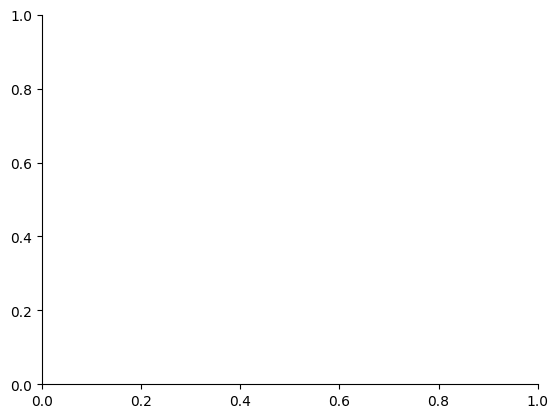

In [ ]:
fig, ax = plt.subplots()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

params = {'legend.fontsize': 12,
          'axes.labelsize': 15,
          'axes.titlesize': 15,
          'xtick.labelsize': 15,
          'ytick.labelsize': 15,
          'text.usetex': False,
          #'font.family': "Times New Roman",
          'text.latex.preamble': r'\usepackage{amsfonts}'}
plt.rcParams.update(params)

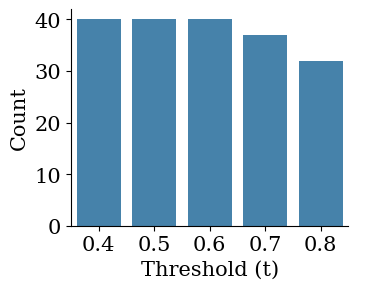

In [ ]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']


g = sns.catplot(
    data=Vis_df, kind="bar",
    x="Threshold", y="Count",
    alpha=.9, height=3, aspect=1.2,
    #palette = 'Blues'
)

g.set(xlabel='Threshold (t)')
#g.set(yticks=[0,10,20,30,40])
#g.ax.set_xticklabels(subnet,rotation=30, ha='right')

plt.savefig('/content/drive/MyDrive/brain_data/Vis_testing.svg', format='svg',bbox_inches="tight")

In [ ]:
subnet = ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']
nodes = [61,77,46,47,26,52,91]

sub_df = pd.DataFrame(
    data = {
        'subnet':subnet,
        'nodes':nodes
    }
)

sub_df = sub_df.sort_values(by='nodes',ascending=False)
sub_df

,subnet,nodes
6,Default,91
1,SomMot,77
0,Vis,61
5,Cont,52
3,SalVentAttn,47
2,DorsAttn,46
4,Limbic,26


<ipython-input-86-0de54633b4cb>:10: UserWarning: FixedFormatter should only be used together with FixedLocator
  g.ax.set_xticklabels(list(sub_df['subnet']),rotation=30, ha='right')


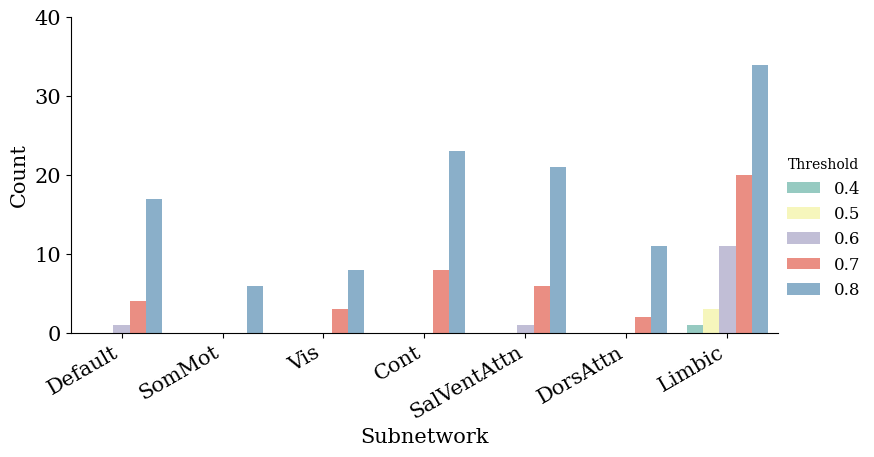

In [ ]:
g = sns.catplot(
    data=result_df, kind="bar",
    x="Cate", y="Count", hue="Threshold",
    order = list(sub_df['subnet']),
    alpha=1., height=4, aspect=2,palette = 'Set3'
)

g.set(xlabel='Subnetwork')
g.set(yticks=[0,10,20,30,40])
g.ax.set_xticklabels(list(sub_df['subnet']),rotation=30, ha='right')

plt.savefig('/content/drive/MyDrive/brain_data/Compare_testing.svg', format='svg',bbox_inches="tight")